In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import sys
import os

# Get the current working directory
cwd = os.getcwd()

# Get the path to the project's root directory
root_path = os.path.abspath(os.path.join(cwd, os.pardir))

# Add the project's root directory to the Python module search path
sys.path.append(root_path)

## Example

Given a system of linear equations represented as a square matrix $A$, our goal is to solve $Ax = b$ by first transforming the augmented matrix $[A|b]$ to upper triangular form (all entries below the main diagonal are zero) through Gaussian elimination, and then applying back substitution. 

The implementation performs this elimination internally and returns only the solution vector $x$ (not the triangular matrix itself). The Gaussian elimination process involves three types of operations:

1. Swapping two rows,
2. Multiplying a row by a non-zero scalar,
3. Adding a multiple of one row to another row.

Given a matrix $A = \begin{bmatrix} 2 & 3 \\ 4 & -1 \end{bmatrix}$, the following Python code solves the system $Ax = b$ with $b = \begin{bmatrix} 12 \\ 10 \end{bmatrix}$ using Gaussian elimination (with partial pivoting and back substitution) and prints the returned solution vector. A singular or nearly singular matrix raises a `ValueError`.

In [2]:
from implementation.gaussian_elimination import gaussian_elimination


def plot_matrix(matrix, name=""):
    # Converting the matrix into a DataFrame
    df = pd.DataFrame(matrix)

    # Converting all columns to float
    df = df.astype(np.float64)

    # Converting DataFrame to string and hiding index and columns
    df_str = df.to_string(float_format="{:.2f}".format, index=False, header=False)

    print(f"{name} matrix:")
    print(f"{df_str}\n")


# Create a 2D array and a right-hand side vector
matrix = np.array([[2, 3], [4, -1]])
b = np.array([12, 10])
solution = gaussian_elimination(np.copy(matrix), np.copy(b))

plot_matrix(matrix, "Coefficient")
print("Solution x:", solution)

Coefficient matrix:
2.00  3.00
4.00 -1.00

Solution x: [3. 2.]


Consider a system of linear equations that can be represented in matrix form as $Ax = b$, where $A$ is a matrix of coefficients, $x$ is a vector of variables, and $b$ is a vector of constants.

Our goal is to find the solution to this system of equations that satisfies all equations simultaneously. We achieve this through the Gaussian elimination method, which transforms the augmented matrix to upper triangular form, making it easy to find the solution through back substitution.

In addition, we want to visually represent this system of equations and its solution in a two-dimensional plane. Each equation can be represented as a line in this plane, and the solution to the system is the point where all lines intersect.

The Python code provided below does exactly this. It first plots each equation as a line in the 2D plane. The $x$ values are generated using the \texttt{numpy.linspace} function to create an array of evenly spaced values within a specified range. For each $x$ value, the corresponding $y$ value is calculated by rearranging the equation to the form $y = (b - Ax) / A$, where $A$ and $b$ are the coefficients and constants from the matrix and vector respectively.

After plotting all the lines, the code uses the \texttt{solve\_gaussian\_elimination} function to find the solution for $x$. This function returns the same solution as `gaussian_elimination`, rounded to 8 decimal places. The solution is then plotted as a red point on the graph.

Given a matrix $A = \begin{bmatrix} 2 & 3 \\ 4 & -1 \end{bmatrix}$ and a vector $b = \begin{bmatrix} 12 \\ 10 \end{bmatrix}$, the Python code will plot the corresponding system of equations and its solution.


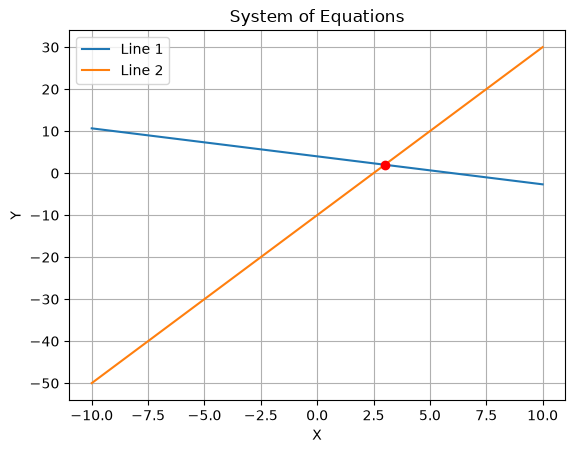

In [3]:
from implementation.gaussian_elimination import solve_gaussian_elimination


def plot_system_of_equations(A, b):
    """Plot a system of equations defined by matrix A and vector b."""

    # Generate a range of x values
    x_values = np.linspace(-10, 10, 400)

    # Plot each equation
    for i in range(A.shape[0]):
        # Calculate the corresponding y values
        y_values = (b[i] - A[i, 0] * x_values) / A[i, 1]
        plt.plot(x_values, y_values, label=f"Line {i + 1}")

    # Solve the system of equations for x
    x = solve_gaussian_elimination(A, b)

    # Plot the solution
    plt.plot(x[0], x[1], "ro")  # solution point

    # Set the labels and title
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title("System of Equations")

    # Show the legend
    plt.legend()

    # Show the plot
    plt.grid()
    plt.show()


A = np.array([[2, 3], [4, -1]])
b = np.array([12, 10])
plot_system_of_equations(A, b)